
## «Диаграммы, графики и их построение»





## 1. Загрузка и просмотр датасета
Загрузим Excel-файл, выведем первые строки и размерность набора данных. Каждая строка соответствует транзакции.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

df = pd.read_excel("Coffee_Shop_Sales.xlsx")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)

print("Вариант 3. Продажи кофейни")
print(f"Размерность датасета: {df.shape[0]:,} строк и {df.shape[1]} столбцов")
display(df.head(10))

Вариант 3. Продажи кофейни
Размерность датасета: 149,116 строк и 11 столбцов


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.00,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.10,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.50,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.00,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.10,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
5,6,2023-01-01,07:22:41,1,5,Lower Manhattan,77,3.00,Bakery,Scone,Oatmeal Scone
6,7,2023-01-01,07:25:49,1,5,Lower Manhattan,22,2.00,Coffee,Drip coffee,Our Old Time Diner Blend Sm
7,8,2023-01-01,07:33:34,2,5,Lower Manhattan,28,2.00,Coffee,Gourmet brewed coffee,Columbian Medium Roast Sm
8,9,2023-01-01,07:39:13,1,5,Lower Manhattan,39,4.25,Coffee,Barista Espresso,Latte Rg
9,10,2023-01-01,07:39:34,2,5,Lower Manhattan,58,3.50,Drinking Chocolate,Hot chocolate,Dark chocolate Rg


In [12]:
display(pd.DataFrame({"Тип данных": df.dtypes.astype(str), "Пропуски": df.isna().sum()}))

,Тип данных,Пропуски
transaction_id,int64,0
transaction_date,datetime64[us],0
transaction_time,object,0
transaction_qty,int64,0
store_id,int64,0
store_location,str,0
product_id,int64,0
unit_price,float64,0
product_category,str,0
product_type,str,0


## Подготовка данных
Добавим вычисляемую выручку по каждой транзакции. Затем подготовим таблицы по месяцам, категориям и магазинам. 

In [13]:
data = df.copy()
data["revenue"] = data["transaction_qty"] * data["unit_price"]
data["month"] = data["transaction_date"].dt.to_period("M").astype(str)
monthly_revenue = data.groupby("month", as_index=False)["revenue"].sum()
category_revenue = data.groupby("product_category")["revenue"].sum().sort_values(ascending=False)
store_category = data.pivot_table(index="product_category", columns="store_location",
                                  values="revenue", aggfunc="sum", fill_value=0)
print("Период:", data.transaction_date.min().date(), "—", data.transaction_date.max().date())
print("Количество транзакций:", len(data))
print("Общая выручка:", round(data.revenue.sum(), 2))

Период: 2023-01-01 — 2023-06-30
Количество транзакций: 149116
Общая выручка: 698812.33


## 2. Линейный график: динамика выручки по месяцам
Линейный график подходит, потому что в датасете есть дата транзакции. Месяцы имеют естественный хронологический порядок, поэтому можно проследить изменение выручки во времени.

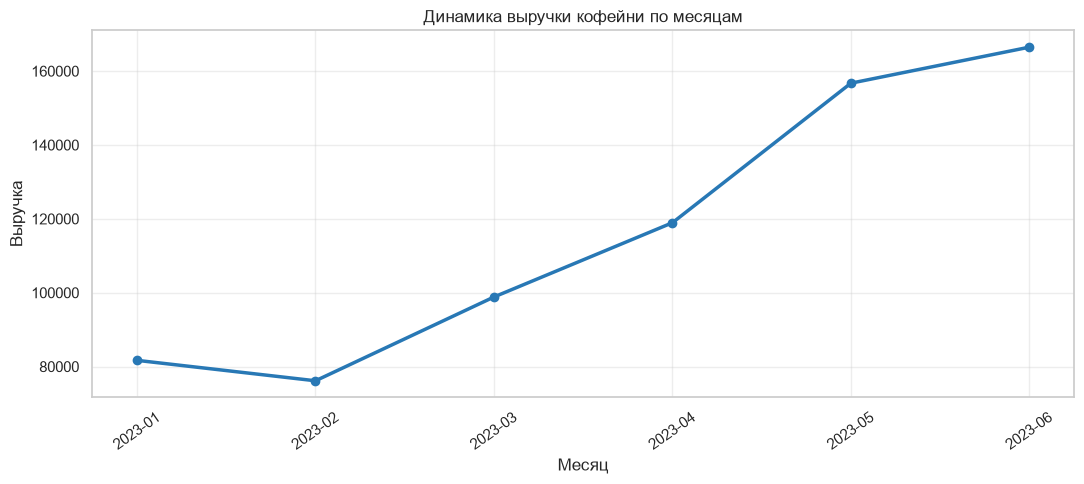

,month,revenue
0,2023-01,81677.74
1,2023-02,76145.19
2,2023-03,98834.68
3,2023-04,118941.08
4,2023-05,156727.76
5,2023-06,166485.88


In [14]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(monthly_revenue["month"], monthly_revenue["revenue"],
        marker="o", linewidth=2.5, color="#2878B5")
ax.set_title("Динамика выручки кофейни по месяцам")
ax.set_xlabel("Месяц")
ax.set_ylabel("Выручка")
ax.tick_params(axis="x", rotation=35)
ax.grid(True, alpha=0.35)
plt.tight_layout()
plt.show()
display(monthly_revenue)

**Код.** `groupby("month")` объединяет транзакции по месяцам, `sum()` складывает выручку, а `ax.plot()` соединяет месячные значения линией. Маркеры `o` обозначают отдельные месяцы.

**Интерпретация.** Рост линии означает увеличение выручки, снижение — её уменьшение. По выведенной таблице можно определить точные значения для каждого месяца, а по линии — быстро увидеть общую динамику. Линейный график подходит, поскольку порядок месяцев имеет значение.

## 3. Круговая диаграмма: доли категорий в общей выручке
В наборе девять категорий. Чтобы сектора оставались читаемыми, покажем пять крупнейших категорий, а остальные объединим в сектор «Прочее». Все доли рассчитываются от общей выручки.

In [ ]:
top_n = 5
pie_data = category_revenue.head(top_n).copy()
pie_data.loc["Прочее"] = category_revenue.iloc[top_n:].sum()

fig, ax = plt.subplots(figsize=(8, 7))
ax.pie(pie_data.values, labels=pie_data.index, autopct="%1.1f%%",
       startangle=90, pctdistance=0.72,
       wedgeprops={"edgecolor": "white", "linewidth": 1.5})
ax.set_title("Структура выручки по категориям товаров")
plt.tight_layout()
plt.show()
display(pie_data.rename("Выручка").to_frame())

**Код.** `head(5)` выбирает пять категорий с наибольшей выручкой. Остальные суммируются в «Прочее». `ax.pie()` строит круг, а `autopct` подписывает доли в процентах.

**Интерпретация.** Размер сектора показывает вклад категории в общую выручку. Чем больше сектор, тем выше вклад категории. Объединение небольших категорий упрощает чтение диаграммы. Круговая диаграмма подходит, потому что категории являются частями одной общей суммы.

## 4. Вертикальная, горизонтальная и сгруппированная столбчатые диаграммы
Столбчатые диаграммы сравнивают категории по величине. В качестве показателя используется суммарная выручка. Дополнительно сравним категории между тремя магазинами.

In [ ]:
cat_plot = category_revenue.sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].bar(cat_plot.index, cat_plot.values, color="#4C9F70")
axes[0].set_title("Вертикальная диаграмма")
axes[0].set_xlabel("Категория")
axes[0].set_ylabel("Выручка")
axes[0].tick_params(axis="x", rotation=55)
axes[1].barh(cat_plot.index[::-1], cat_plot.values[::-1], color="#D18B47")
axes[1].set_title("Горизонтальная диаграмма")
axes[1].set_xlabel("Выручка")
axes[1].set_ylabel("Категория")
plt.tight_layout()
plt.show()

**Код.** `ax.bar()` строит вертикальные столбцы, `ax.barh()` — горизонтальные. Категории предварительно сортируются по убыванию выручки.

**Интерпретация.** Самые высокие или длинные столбцы соответствуют категориям с наибольшей выручкой. Горизонтальный вариант удобнее при длинных названиях, так как подписи остаются читаемыми.

In [ ]:
grouped_data = store_category.copy()
ax = grouped_data.plot(kind="bar", figsize=(13, 6), width=0.82)
ax.set_title("Выручка по категориям в разных магазинах")
ax.set_xlabel("Категория товара")
ax.set_ylabel("Выручка")
ax.tick_params(axis="x", rotation=45)
ax.legend(title="Магазин")
plt.tight_layout()
plt.show()

**Сгруппированная диаграмма.** `pivot_table()` заранее собрал выручку по двум признакам: категории и местоположению магазина. Для каждой категории рядом расположены столбцы трёх магазинов.

**Интерпретация.** График позволяет сравнить торговые точки внутри каждой категории. Если столбец одного магазина выше, значит, его выручка в данной категории больше. Различия могут быть связаны с расположением магазина и предпочтениями покупателей.

## 5. Горизонтальная диаграмма с накоплением
Выручка категории складывается из выручки трёх магазинов, поэтому накопление здесь имеет смысл. Диаграмма покажет одновременно итог по категории и вклад каждой торговой точки.

In [ ]:
stacked_data = store_category.copy()
stacked_data["Итого"] = stacked_data.sum(axis=1)
stacked_data = stacked_data.sort_values("Итого", ascending=True).drop(columns="Итого")
ax = stacked_data.plot(kind="barh", stacked=True, figsize=(11, 6),
                       color=["#3478A8", "#E39C37", "#5A9B75"])
ax.set_title("Общая выручка по категориям и вклад магазинов")
ax.set_xlabel("Выручка")
ax.set_ylabel("Категория товара")
ax.legend(title="Магазин")
plt.tight_layout()
plt.show()

**Код.** Сначала вычисляется общий итог для сортировки категорий. Затем `plot(kind="barh", stacked=True)` размещает сегменты магазинов последовательно в одной горизонтальной полосе.

**Интерпретация.** Полная длина полосы показывает общую выручку категории, а цветные сегменты — вклад отдельных магазинов. Накопление подходит, потому что значения являются частями одной суммарной величины.

## 6. Гистограмма: распределение цены товара
Для гистограммы выберем `unit_price` — цену одной единицы товара. Используем 30 интервалов. В датасете много транзакций и заметный разброс цен, поэтому такое число позволяет рассмотреть основную форму распределения без чрезмерной детализации.

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(data["unit_price"], bins=30, color="#6C8EBF", edgecolor="white")
ax.set_title("Распределение цены одной единицы товара")
ax.set_xlabel("Цена")
ax.set_ylabel("Количество транзакций")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
display(data["unit_price"].describe().to_frame("Статистика"))

**Код.** `ax.hist()` делит диапазон цен на 30 интервалов (`bins=30`) и подсчитывает количество значений в каждом. Белая обводка помогает различать соседние столбцы.

**Интерпретация.** Высота столбца показывает, сколько транзакций попало в соответствующий ценовой интервал. Основная масса значений сосредоточена в наиболее частых ценовых диапазонах, а редкие высокие цены формируют правый хвост. Гистограмма помогает увидеть форму распределения и наличие редких значений.

## 7. Диаграмма рассеяния: количество товара и выручка транзакции
В датасете есть две числовые переменные: `transaction_qty` и рассчитанная `revenue`. Каждая точка соответствует одной транзакции. Для оценки линейной связи дополнительно рассчитаем корреляцию Пирсона.

In [ ]:
corr = data["transaction_qty"].corr(data["revenue"])
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(data["transaction_qty"], data["revenue"],
           alpha=0.18, s=16, color="#C76D3A", edgecolors="none")
ax.set_title("Связь количества товара и выручки транзакции")
ax.set_xlabel("Количество единиц товара")
ax.set_ylabel("Выручка транзакции")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print(f"Коэффициент корреляции Пирсона: {corr:.3f}")

**Код.** `ax.scatter(x, y)` размещает точку для каждой пары значений. `alpha` задаёт прозрачность, чтобы большое количество точек не сливалось. Корреляция Пирсона принимает значения от −1 до 1: положительное значение означает прямую линейную связь, отрицательное — обратную.

**Интерпретация.** График позволяет оценить, увеличивается ли выручка при росте количества товара. Точки могут быть разбросаны, поскольку выручка зависит не только от количества, но и от цены товара. Коэффициент корреляции помогает оценить силу линейной связи. Отдельные очень большие значения могут быть выбросами или крупными покупками. Корреляция сама по себе не доказывает причинно-следственную зависимость.

## 8. Ящик с усами (boxplot): распределение выручки транзакции
Ящик с усами показывает медиану, межквартильный размах и выбросы. Выбросы определяются по правилу 1,5 × IQR.

In [ ]:
q1 = data["revenue"].quantile(0.25)
median = data["revenue"].median()
q3 = data["revenue"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outliers = data[(data["revenue"] < lower_bound) | (data["revenue"] > upper_bound)]

fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(x=data["revenue"], color="#8CCB9B", ax=ax)
ax.set_title("Ящик с усами для выручки одной транзакции")
ax.set_xlabel("Выручка транзакции")
plt.tight_layout()
plt.show()

print(f"Q1 (25%): {q1:.2f}")
print(f"Медиана: {median:.2f}")
print(f"Q3 (75%): {q3:.2f}")
print(f"IQR = Q3 - Q1: {iqr:.2f}")
print(f"Нижняя граница: {lower_bound:.2f}")
print(f"Верхняя граница: {upper_bound:.2f}")
print(f"Количество выбросов: {len(outliers):,}")

**Код.** `quantile()` рассчитывает первый и третий квартили. Межквартильный размах равен `Q3 - Q1`. Границы выбросов вычисляются как `Q1 - 1,5 × IQR` и `Q3 + 1,5 × IQR`. `sns.boxplot()` строит график.

**Интерпретация.** Линия внутри ящика — медиана, границы ящика — первый и третий квартили, а сам ящик содержит центральные 50% наблюдений. Усы показывают крайние значения, не выходящие за границы правила 1,5 × IQR. Точки за усами считаются статистическими выбросами. Большая транзакция не обязательно является ошибкой: она может отражать крупную покупку.

## 9. Сравнение matplotlib и seaborn на одной задаче
Сравним среднюю выручку транзакции между магазинами двумя способами. В matplotlib статистику рассчитаем самостоятельно, а в seaborn передадим исходную таблицу.

In [ ]:
# Способ 1. Matplotlib: статистика рассчитывается вручную
store_stats = (data.groupby("store_location")["revenue"]
               .agg(["mean", "std"]).sort_values("mean", ascending=False))
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(store_stats.index, store_stats["mean"], yerr=store_stats["std"],
       capsize=5, color=["#3478A8", "#E39C37", "#5A9B75"])
ax.set_title("Средняя выручка транзакции по магазинам (matplotlib)")
ax.set_xlabel("Магазин")
ax.set_ylabel("Средняя выручка")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()
display(store_stats)

**Код matplotlib.** `groupby()` группирует транзакции по магазинам, `agg()` вручную рассчитывает среднее и стандартное отклонение. `ax.bar()` строит столбцы, а `yerr` добавляет линии разброса. Нужно самостоятельно подготовить статистику, зато есть полный контроль над графиком.

In [ ]:
# Способ 2. Seaborn: группировка и среднее рассчитываются библиотекой
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=data, x="store_location", y="revenue", hue="store_location",
            estimator="mean", errorbar="sd", ax=ax, palette="Set2", legend=False)
ax.set_title("Средняя выручка транзакции по магазинам (seaborn)")
ax.set_xlabel("Магазин")
ax.set_ylabel("Средняя выручка")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

**Код seaborn.** `sns.barplot()` получает исходную таблицу и названия столбцов. `estimator="mean"` задаёт среднее значение, а `errorbar="sd"` отображает стандартное отклонение. Seaborn сам группирует данные, поэтому отдельная таблица средних для построения не требуется.

**Сравнение.** Matplotlib требует больше подготовительных действий, так как статистику нужно рассчитать самостоятельно. Он удобен для нестандартного оформления и полного контроля. Seaborn позволяет короче построить типовой статистический график непосредственно из DataFrame. В этой задаче seaborn удобнее по объёму кода, а matplotlib полезен, когда требуется детально управлять каждым элементом. Seaborn работает поверх matplotlib, поэтому библиотеки дополняют друг друга.

## Общий вывод
В ходе практической работы был изучен датасет о продажах кофейни и построены основные виды диаграмм с помощью `matplotlib` и `seaborn`.

Линейный график позволил рассмотреть изменение выручки по месяцам. Круговая диаграмма показала вклад категорий в общую выручку. Вертикальные, горизонтальные и сгруппированные столбчатые диаграммы помогли сравнить категории и торговые точки. Диаграмма с накоплением показала общий результат и вклад каждого магазина. Гистограмма отобразила распределение цен, диаграмма рассеяния помогла оценить связь количества товара с выручкой, а boxplot показал медиану, межквартильный размах и выбросы.

Также одна задача была решена двумя библиотеками. Matplotlib требует больше ручной подготовки, но предоставляет гибкую настройку. Seaborn позволяет быстрее строить статистические графики на основе таблиц pandas. Выбор библиотеки зависит от задачи и необходимого уровня контроля над визуализацией.